In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
PROJECT_ROOT = Path.cwd().parent          # notebooks/ -> market-analyzer/
df = pd.read_parquet(PROJECT_ROOT / "data/processed/listings_clean.parquet")
print(f"Shape: {df.shape}")
print(f"Columns: {len(df.columns)}")

Shape: (16558, 94)
Columns: 94


In [2]:
df[["price", "accommodates", "bedrooms", "bathrooms",
    "amenity_count", "distance_to_center_km"]].describe()

,price,accommodates,bedrooms,amenity_count,distance_to_center_km
count,"16,558.00","16,558.00","16,553.00","16,558.00","16,558.00"
mean,"6,321.84",3.73,1.46,33.42,7.53
std,"10,311.44",2.26,1.16,15.28,10.71
min,320.00,1.00,0.00,0.00,0.04
25%,"3,000.00",2.00,1.00,23.00,2.65
50%,"4,469.75",3.00,1.00,34.00,3.76
75%,"6,856.57",4.00,2.00,44.00,6.66
max,"502,353.28",16.00,50.00,97.00,81.19


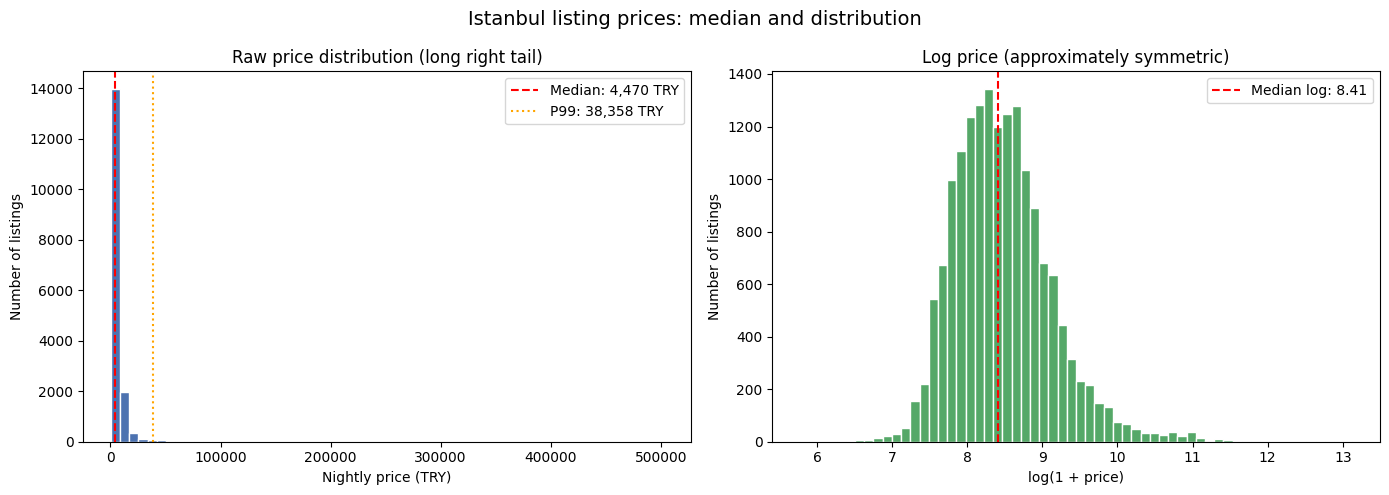

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Left panel: raw price ----
axes[0].hist(df["price"], bins=60, color="#4C72B0", edgecolor="white")
axes[0].axvline(df["price"].median(), color="red", linestyle="--",
                label=f"Median: {df['price'].median():,.0f} TRY")
axes[0].axvline(df["price"].quantile(0.99), color="orange", linestyle=":",
                label=f"P99: {df['price'].quantile(0.99):,.0f} TRY")
axes[0].set_xlabel("Nightly price (TRY)")
axes[0].set_ylabel("Number of listings")
axes[0].set_title("Raw price distribution (long right tail)")
axes[0].legend()

# ---- Right panel: log price ----
axes[1].hist(df["price_log"], bins=60, color="#55A868", edgecolor="white")
axes[1].axvline(df["price_log"].median(), color="red", linestyle="--",
                label=f"Median log: {df['price_log'].median():.2f}")
axes[1].set_xlabel("log(1 + price)")
axes[1].set_ylabel("Number of listings")
axes[1].set_title("Log price (approximately symmetric)")
axes[1].legend()

fig.suptitle("Istanbul listing prices: median and distribution", fontsize=14)
fig.tight_layout()
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent          # notebooks/ -> market-analyzer/
out_path = PROJECT_ROOT / "reports/eda/price_distribution.png"
out_path.parent.mkdir(parents=True, exist_ok=True)   # create reports/eda/ if missing

fig.savefig(out_path, dpi=160, bbox_inches="tight")
plt.show()

In [9]:
print(df['price'].quantile(0.25))


3000.0


In [ ]:
print(df['price'].quantile(0.75))

6856.5675


In [12]:
print(df['price'].max())

502353.28


In [13]:
df.groupby("neighbourhood_cleansed").agg(
    median_price=("price", "median"),
    listings=("listing_id", "count"),
)

,median_price,listings
neighbourhood_cleansed,,
Adalar,"6,688.00",151
Arnavutkoy,"3,444.00",189
Atasehir,"4,737.50",166
Avcilar,"2,300.00",86
Bagcilar,"5,837.00",248
Bahcelievler,"4,364.00",553
Bakirkoy,"4,014.00",144
Basaksehir,"5,485.67",51
Bayrampasa,"5,796.00",18


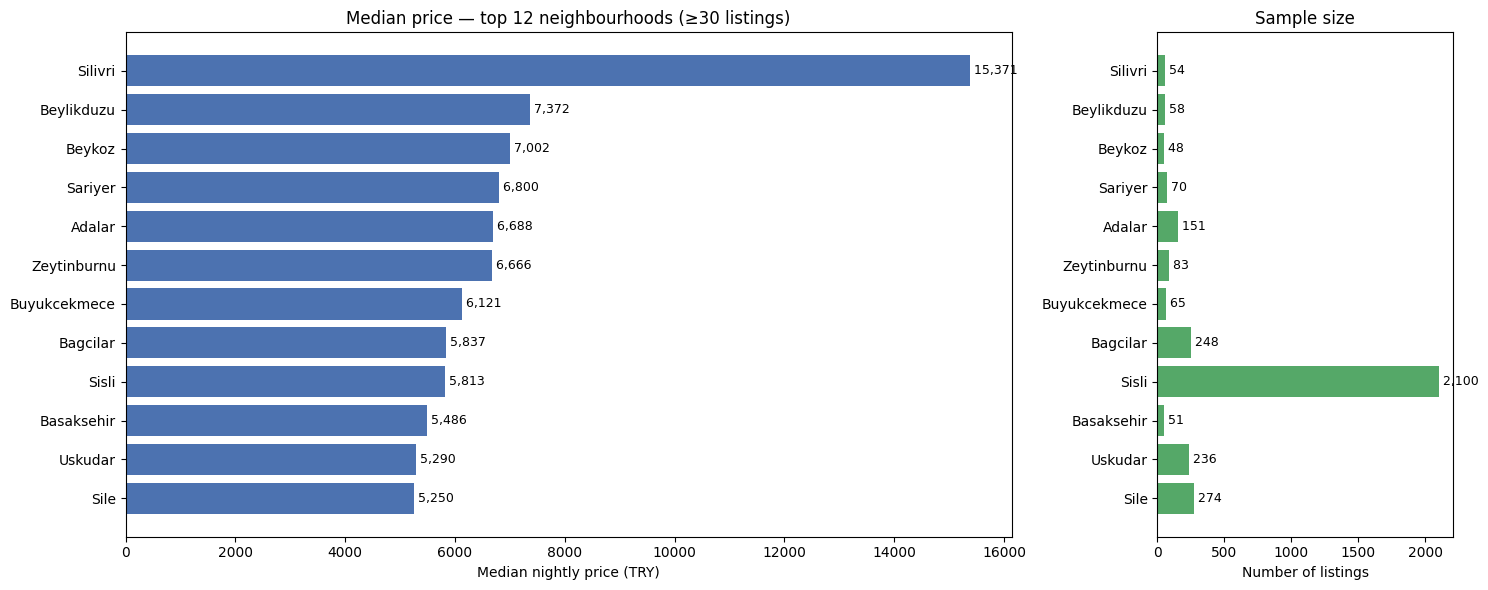

                        median_price  mean_price  listings
neighbourhood_cleansed                                    
Silivri                    15,370.94   32,688.78        54
Beylikduzu                  7,372.50    9,508.76        58
Beykoz                      7,002.50    9,376.12        48
Sariyer                     6,800.00   13,101.74        70
Adalar                      6,688.00    7,959.61       151
Zeytinburnu                 6,666.00    9,114.22        83
Buyukcekmece                6,121.00    9,658.60        65
Bagcilar                    5,837.00    7,489.60       248
Sisli                       5,812.64    7,612.16      2100
Basaksehir                  5,485.67    5,454.27        51
Uskudar                     5,289.90    6,575.30       236
Sile                        5,249.50    7,141.46       274


In [17]:
neighbourhood_summary = (
    df.groupby("neighbourhood_cleansed")
    .agg(
        median_price=("price", "median"),
        listings=("listing_id", "count"),
        mean_price=("price", "mean"),
    )
    .query("listings >= 30")
    .sort_values("median_price", ascending=False)
)

top = neighbourhood_summary.head(12).iloc[::-1]   # reverse for horizontal bar order

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [3, 1]})

# Left: median price bars
axes[0].barh(top.index, top["median_price"], color="#4C72B0")
axes[0].set_xlabel("Median nightly price (TRY)")
axes[0].set_title(f"Median price — top 12 neighbourhoods (≥30 listings)")
for i, v in enumerate(top["median_price"]):
    axes[0].text(v, i, f" {v:,.0f}", va="center", fontsize=9)

# Right: listing counts
axes[1].barh(top.index, top["listings"], color="#55A868")
axes[1].set_xlabel("Number of listings")
axes[1].set_title("Sample size")
for i, v in enumerate(top["listings"]):
    axes[1].text(v, i, f" {v:,}", va="center", fontsize=9)

fig.tight_layout()
fig.savefig(out_path, dpi=160, bbox_inches="tight")
plt.show()

# Also print the table for evidence
print(neighbourhood_summary.head(12)[["median_price", "mean_price", "listings"]])